In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


**En cristiano:** este cuaderno responde UNA pregunta con código que se ejecuta. Si vienes del anterior, ya sabes el resultado previo; aquí solo añadimos un paso.


# 04 · Beta OOF y ensamble — cuánto del meta nos creemos

Parte 2 de 3. Mismo código que las secciones 7–8 del original.

**Requisito:** haber corrido el `01` (usa su `artifacts/`). No re-entrena la semilla 42.


In [2]:
# FIX ruta: los cuadernos viven en notebooks/ds02_ensemble pero los datos estan en la raiz.
# Se vuelve a la raiz para que archive/... y models/... resuelvan igual que en el original.
import pathlib as _pl
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
import os as _os
_os.chdir(_ROOT)
print("cwd:", _os.getcwd())
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd

import ds02_rul
from ds02_rul import calculate_nasa_score, evaluate_predictions, macro_rmse
from ds02_rul.conformal import apply_conformal, empirical_coverage, fit_conformal
from ds02_rul.data import load_ds02
from ds02_rul.features import build_windows, fit_preprocessing
from ds02_rul.model import build_champion_bilstm
from ds02_rul.persistence import build_manifest, load_ensemble, save_ensemble
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import (
    fit_meta_learners, in_sample_beta_diagnostic, meta_predict, select_beta_grouped,
)
from ds02_rul.pipeline import (
    ablation_table, make_lgbm, oof_base_predictions, run_seed, seed_summary,
)

import keras
import lightgbm as lgb
import sklearn

SEEDS = [42, 7, 123]
PRIMARY_SEED = SEEDS[0]
WINDOW_SIZE = 50
STEP_TRAIN = 3
STEP_TEST = 2

print('python  :', sys.version.split()[0])
print('keras   :', keras.__version__)
print('lightgbm:', lgb.__version__)
print('sklearn :', sklearn.__version__)
print('ds02_rul:', ds02_rul.__version__, '->', os.path.dirname(ds02_rul.__file__))


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


python  : 3.12.10
keras   : 3.15.1
lightgbm: 4.7.0
sklearn : 1.9.1
ds02_rul: 4.1.0 -> C:\Users\mikel\Desktop\Pruebas\nasa\src\ds02_rul


### Glosario en 30 segundos (estilo clase)

| Nombre | Qué es | Dónde vive |
|---|---|---|
| `WINDOW=50` | 50 lecturas seguidas = 1 ventana | `features.py:build_windows` |
| `STEP 3/2` | Separación entre ventanas (train/test) | `pipeline.py:run_seed` |
| `BETA` | Cuánto manda el meta (mediana OOF, `1.0`) | `stacking.py:select_beta_grouped` |
| `EMA5` | Suavizado causal por motor | `smoothing.py:causal_ema_by_unit` |
| `L_inf` | Peor caso de la banda 90% | `conformal.py:apply_conformal` |
| `OOF` | Cada ventana la puntúa otro motor | `pipeline.py:oof_base_predictions` |
| `macro` | Cada motor pesa 1/3 | `metrics.py:macro_rmse` |


In [3]:
# Puente: recupera lo calculado en NB1 (no re-entrena la semilla 42)
import pathlib, joblib, numpy as np, pandas as pd
from ds02_rul.data import load_ds02
ART = _ROOT / "notebooks" / "ds02_ensemble" / "artifacts"
assert (ART / "nb1_dev.npz").exists(), "Falta NB1: ejecuta primero 01_datos_y_bases.ipynb"
d = np.load(ART / "nb1_dev.npz"); t = np.load(ART / "nb1_test.npz")
aux = joblib.load(ART / "nb1_aux.joblib")
ra = joblib.load(ART / "nb1_result_arrays.joblib")
from keras.models import load_model
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]; TEST_UNITS = [11.0, 14.0, 15.0]
raw = load_ds02(stride=100)
prep = aux["prep"]; fit_idx = aux["fit_idx"]; hold_idx = aux["hold_idx"]
dev_units = aux["dev_units"]; lgbm = aux["lgbm"]
p_lgb_hold = aux["p_lgb_hold"]; p_lgb_test = aux["p_lgb_test"]
dev = {"X_seq": d["X_seq"], "X_tab": d["X_tab"], "y": d["y"], "X_raw": d["X_raw"],
       "meta": pd.DataFrame({"unit": d["meta_unit"], "cycle": d["meta_cycle"]})}
test = {"X_seq": t["X_seq"], "X_tab": t["X_tab"], "y": t["y"], "X_raw": t["X_raw"],
        "meta": pd.DataFrame({"unit": t["meta_unit"], "cycle": t["meta_cycle"]})}
bilstm = load_model(ART / "bilstm_seed42.keras")
result = {"bilstm": bilstm, "lgbm": lgbm, "prep": prep, "dev": dev, "test": test,
          "fit_idx": fit_idx, "hold_idx": hold_idx,
          "p_lstm_hold": ra["p_lstm_hold"], "p_lstm_test": ra["p_lstm_test"],
          "p_lgb_hold": ra["p_lgb_hold"], "p_lgb_test": ra["p_lgb_test"],
          "t_lgb": ra["t_lgb"], "t_lstm": ra["t_lstm"], "history": type("H", (), {"history": ra["history"]})()}
print("[LOAD NB1 OK] dev", dev["X_seq"].shape, "| test", test["X_seq"].shape, "| bilstm recargado")


[LOAD NB1 OK] dev (17450, 50, 19) | test (6196, 50, 19) | bilstm recargado


In [4]:
# 2. Alias estilo clase (solo lectura: no entrenan, no cambian numeros).
#    evaluar_clase/mostrar_clase ya vienen de viz (ver src/ds02_rul/viz.py).
from ds02_rul.viz import evaluar_clase, mostrar_clase
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


In [5]:
dev_units = aux["dev_units"]
from ds02_rul.pipeline import oof_base_predictions
PRIMARY_SEED = 42
WINDOW_SIZE = 50
STEP_TRAIN = 1
# OOF en vivo (~4-5 min): cada ventana la puntúa un meta que nunca la vio entrenar
import time
t0 = time.time()
oof = oof_base_predictions(raw, dev_units, n_splits=3, seed=PRIMARY_SEED,
                           window=WINDOW_SIZE, step_train=STEP_TRAIN, epochs=15,
                           use_cycle=True)
print(f'OOF base predictions en {time.time()-t0:.1f} s')
print('folds:', oof['unit_folds'])


OOF base predictions en 1200.2 s
folds: [[2.0, 10.0], [5.0, 18.0], [20.0, 16.0]]


> TIP En resumen (para presentar): Dos especialistas ven mejor que uno. BiLSTM lee la pelicula temporal de la ventana (inercia, triple-pooling: ultimo+media+maximo) y LightGBM evalua estadisticas del residuo. El meta-modelo los combina con `beta` elegido fuera de fold (mediana agrupada, `beta=1.0`) y el filtro EMA causal (`ema_span=5`) evita que la alarma parpadee. El OOF agrupado garantiza que cada ventana la puntua un meta ajustado en *otros* motores.


## 7 · Calibración fuera de fold de `beta`

`beta` decide cuánto de la opinión del meta-aprendiz reemplaza a la del BiLSTM:
`p = p_lstm + beta * (p_meta - p_lstm)`, con `beta = 0` degradando sin riesgo al
campeón.

Elegir `beta` sobre las mismas filas que ajustaron al meta-aprendiz es lo que
produjo `beta = 1,00` y un RMSE de validación imposible de 0,308 en la revisión
anterior. Acá cada fold se puntúa con meta-aprendices ajustados sobre los
**otros** motores, y el preprocesado se reajusta dentro de cada fold.

Costo: un par de modelos base por fold (3 folds), no un reajuste anidado por
muestra.


In [6]:
selection = select_beta_grouped(oof['units'], oof['cycles'], oof['y'],
                                oof['pred_lstm'], oof['pred_lgb'],
                                span=5, use_cycle_feature=False)

print(f"beta_hat (mediana de los folds) = {selection['beta']:.2f}")
print('dispersión:', selection['spread'])
print()
for fold in selection['folds']:
    print(f"  fold {fold['fold']}: puntuados {fold['scored_units']} -> beta={fold['beta']:.2f} "
          f"| rmse {fold['rmse_val']:.3f} (ref BiLSTM {fold['rmse_lstm_ref']:.3f}) "
          f"| nasa {fold['nasa_val']:.1f} (ref {fold['nasa_lstm_ref']:.1f})")


beta_hat (mediana de los folds) = 1.00
dispersión: {'min': 0.0, 'max': 1.0, 'iqr': 0.5, 'n_folds': 3}

  fold 0: puntuados [2.0, 10.0] -> beta=1.00 | rmse 8.036 (ref BiLSTM 9.304) | nasa 15107.0 (ref 17312.1)
  fold 1: puntuados [5.0, 18.0] -> beta=1.00 | rmse 9.658 (ref BiLSTM 10.517) | nasa 18884.0 (ref 21913.7)
  fold 2: puntuados [16.0, 20.0] -> beta=0.00 | rmse 4.996 (ref BiLSTM 5.017) | nasa 8056.9 (ref 8093.1)


## Meta en vivo: solo holdout-16, sin `cyc_norm` a proposito

**En cristiano:** el meta-aprendiz no mira sensores ni ciclos. Solo mira dos numeros por ventana: lo que dice la red (`p_lstm`) y lo que dice el arbol (`p_lgb`). Con esas dos columnas (`Z`, sin reloj) ajustamos dos mezcladores — `RidgeCV` (lineal) y un `LGBMRegressor` pequeno — y la prediccion final del meta es `0.5 * Ridge + 0.5 * LGBM`.

**Por que sin `cyc_norm`:** si le das el reloj al meta, pone ~100% del peso en el reloj e ignora a los dos especialistas. El `cyc_norm` ya hizo su trabajo abajo (canal 19 de la BiLSTM); arriba estorba. La celda lo deja por escrito con `Z.shape[1] == 2`.


In [7]:
# Meta en vivo: se ajusta SOLO en holdout-16 (2535 ventanas), sin cyc_norm a propósito
# Con cyc_norm el meta pondría ~100% del peso en el reloj e ignoraría las ramas.
from ds02_rul.stacking import fit_meta_learners, meta_predict
hold_cycles = dev['meta']['cycle'].values[hold_idx]
hold_units = dev['meta']['unit'].values[hold_idx]
y_hold = dev['y'][hold_idx]
Z_hold = np.column_stack([result['p_lstm_hold'], result['p_lgb_hold']])
ridge_meta, lgb_meta = fit_meta_learners(Z_hold, y_hold, seed=PRIMARY_SEED)
BETA = selection['beta']
print(f'meta en {len(y_hold)} ventanas motor 16 | ridge alpha {ridge_meta.alpha_:.4g} coef {np.round(ridge_meta.coef_,4).tolist()} | beta={BETA:.2f}')


meta en 2535 ventanas motor 16 | ridge alpha 14.38 coef [0.1684, 0.7312] | beta=1.00


## 8 · Evaluación híbrida sobre los motores de test

Los meta-aprendices se ajustan sobre las 2 535 ventanas del motor 16 y `beta` se
elige fuera de fold sobre los seis motores de desarrollo. **Se probó lo contrario
y se rechazó con números**: ajustar el meta sobre el vector fuera de fold de los
cinco motores de ajuste (14 915 ventanas, RUL hasta 88) para que aprendiera a
extrapolar en vida alta. Sobre el motor 16 ese meta predice una media de 39.9
cuando la RUL real media es 31.5, y el error crece de forma monótona con `beta`:
RMSE 4.04 con `beta = 0`, 7.48 con 0.6 y 10.17 con 1. La razón es que los motores
de ajuste viven más que los de test, así que el aprendiz agrupado aprende un
**prior de nivel** que no transfiere. El experimento queda documentado en
`INFORME_motor16_vs_oof.md`; las funciones que lo reproducen siguen en
`ds02_rul.stacking` (`fit_meta_learners`, `score_beta_holdout`).

Las meta-características son **`[p_lstm, p_lgb]`**: dos columnas. `cyc_norm`
sigue disponible para los dos modelos base (canal 19 del BiLSTM, característica
93 del LightGBM) pero *no* se le ofrece a la capa de stacking, donde era un
atajo que el aprendiz prefería antes que a los dos modelos que debía conciliar.


In [8]:
from ds02_rul import HybridStackingEnsemble

ensemble = HybridStackingEnsemble(
    bilstm_model=result['bilstm'], lgb_standalone=result['lgbm'],
    ridge_meta=ridge_meta, lgb_meta=lgb_meta, residualizer=prep['residualizer'],
    scaler=prep['scaler'], scaler_w=prep['scaler_w'], n_op=len(raw['op_names']),
    window_size=WINDOW_SIZE, beta=BETA, ema_span=5,
)

p_ens = ensemble.predict(test['X_raw'], test['meta']['cycle'].values, test['meta']['unit'].values)
p_lstm_ema = causal_ema_by_unit(result['p_lstm_test'], test['meta']['unit'].values,
                               test['meta']['cycle'].values, span=5)

rows = [
    evaluate_predictions(test['y'], result['p_lgb_test'], 'LightGBM (cuantil 0.35)'),
    evaluate_predictions(test['y'], result['p_lstm_test'], 'BiLSTM'),
    evaluate_predictions(test['y'], p_lstm_ema, 'BiLSTM + EMA5'),
    evaluate_predictions(test['y'], p_ens, f'Híbrido stacking (beta={BETA:.2f}) + EMA5'),
]
res = pd.DataFrame(rows)
print(res.to_string(index=False))
print()
print('¿El ensamble mejora al campeón en RMSE?:', rows[3]['RMSE'] < rows[2]['RMSE'])
print('¿El ensamble mejora al campeón en NASA?:', rows[3]['NASA_Score'] < rows[2]['NASA_Score'])


                             Modelo  RMSE   MAE     R2  NASA_Score
            LightGBM (cuantil 0.35) 7.113 5.585 0.8551      5794.9
                             BiLSTM 5.651 4.352 0.9085      3818.9
                      BiLSTM + EMA5 5.625 4.332 0.9094      3801.1
Híbrido stacking (beta=1.00) + EMA5 4.251 3.183 0.9482      2305.1

¿El ensamble mejora al campeón en RMSE?: True
¿El ensamble mejora al campeón en NASA?: True


In [9]:
# Baseline en la tabla titular (SOLO lectura: usa predicciones ya calculadas)
pred_media_nb2 = np.full_like(np.asarray(test["y"]), float(np.asarray(dev["y"])[fit_idx].mean()), dtype=float)
fila_base_nb2 = evaluar_clase("Baseline (media train)", test["y"], pred_media_nb2)
res_con_base = pd.DataFrame([fila_base_nb2] + rows)
display(res_con_base.round(3))
print("Cualquier modelo útil tiene que ganarle al baseline; no entra en la elección.")


,Modelo,RMSE,MAE,R2,NASA_Score
0,Baseline (media train),20.022,17.059,-0.148,48840.3
1,LightGBM (cuantil 0.35),7.113,5.585,0.855,5794.9
2,BiLSTM,5.651,4.352,0.908,3818.9
3,BiLSTM + EMA5,5.625,4.332,0.909,3801.1
4,Híbrido stacking (beta=1.00) + EMA5,4.251,3.183,0.948,2305.1


Cualquier modelo útil tiene que ganarle al baseline; no entra en la elección.


,Modelo,RMSE,MAE,R2,NASA_Score
0,BiLSTM + EMA10,5.592,4.302,0.910,3775.0
1,BiLSTM + EMA5,5.625,4.332,0.909,3801.1
2,BiLSTM + EMA3,5.639,4.344,0.909,3811.7


Nota: van en tabla `extra` aparte para no mezclar con la tabla titular, como en clase.


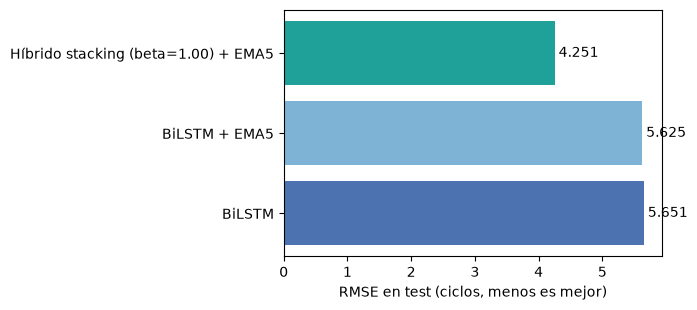

Del BiLSTM al hibrido: +1.400 ciclos de RMSE


In [10]:
# Fase A+B — extras separados + cascada de la decision (SOLO lectura, sin re-entrenar)
# Extra estilo clase: sensibilidad al suavizado EMA sobre el BiLSTM (barato, sin ajustar nada)
from ds02_rul.smoothing import causal_ema_by_unit
units_t = test["meta"]["unit"].values; cycles_t = test["meta"]["cycle"].values
extra = []
for span in [3, 5, 10]:
    pe = causal_ema_by_unit(result["p_lstm_test"], units_t, cycles_t, span=span)
    r = evaluar_clase(f"BiLSTM + EMA{span}", test["y"], pe)
    extra.append(r)
mostrar_clase(extra)
print("Nota: van en tabla `extra` aparte para no mezclar con la tabla titular, como en clase.")

# Cascada RMSE: BiLSTM -> +EMA5 -> hibrido (usa `rows`, ya calculado arriba)
import matplotlib.pyplot as plt
orden = ["BiLSTM", "BiLSTM + EMA5", rows[3]["Modelo"]]
vals = [rows[1]["RMSE"], rows[2]["RMSE"], rows[3]["RMSE"]]
plt.figure(figsize=(7, 3.2))
plt.barh(orden, vals, color=["#4C72B0", "#7FB3D5", "#1FA098"])
plt.xlabel("RMSE en test (ciclos, menos es mejor)")
for i, v in enumerate(vals):
    plt.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()
print(f"Del BiLSTM al hibrido: {rows[1]['RMSE'] - rows[3]['RMSE']:+.3f} ciclos de RMSE")


In [11]:
macro = macro_rmse(test['y'], p_ens, test['meta']['unit'].values)
per_unit = pd.DataFrame([{'motor': int(k), 'RMSE': v}
                        for k, v in macro['per_unit_rmse'].items()])
print('RMSE por motor')
print(per_unit.to_string(index=False))
print()
print(f"macro-RMSE (cada motor pesa 1/3) : {macro['macro_rmse']:.3f}")
print(f"RMSE ponderado por ventana       : {rows[3]['RMSE']:.3f}")
print(f"diferencia                       : {macro['macro_rmse'] - rows[3]['RMSE']:+.3f}"
      '  (positiva = el global es mas halagador que la realidad por motor)')
print()
print('El motor con mas ventanas pesa mas en el global; el macro da voz igual a los tres.')


RMSE por motor
 motor   RMSE
    11 3.7874
    14 7.9974
    15 2.7451

macro-RMSE (cada motor pesa 1/3) : 4.843
RMSE ponderado por ventana       : 4.251
diferencia                       : +0.592  (positiva = el global es mas halagador que la realidad por motor)

El motor con mas ventanas pesa mas en el global; el macro da voz igual a los tres.


> TIP En resumen (para presentar): En aviacion, predecir de mas cuesta un motor en vuelo; predecir de menos solo adelanta una revision. Por eso decidimos sobre `L_inf`, el limite inferior de la banda conformal calibrada fuera de fold al 90% (asimetrica por tramo, `alpha_each_side=0.05`). Si la banda sobre-cubre, se publica el trade-off en vez de estrecharla eligiendo sobre test.


## 9 · Banda conformal: el intervalo honesto (90 %)

**En cristiano:** el punto predice; la banda dice "y me puedo equivocar en esto". Se calibra con residuales **fuera de fold** (`oof_calib`: ventanas que ningun modelo de fold vio entrenar), por bins de prediccion, con cuantiles asimetricos. Tres bandas, una sola enviada:

- **fuera de fold (enviada):** la oficial, calibrada con `fit_conformal` sobre `oof_calib`.
- **motor 16 (diagnostico):** calibrada sobre el holdout-16 con el meta en vivo — mide cuanto cambia la banda con datos del despliegue real.
- **sin sesgo (diagnostico):** `debias=True` — quita la mediana del residual por bin para medir dispersion sin absorber el sesgo del modelo.

**Como leer la tabla:** cobertura % (objetivo 90), ancho medio (ciclos), y por donde se escapa (por debajo / por encima).


In [12]:
# Banda en vivo: se calibra SOLO con residuales fuera de fold (nada de test)
from ds02_rul.conformal import fit_conformal
from ds02_rul.stacking import meta_predict
calib = selection['oof_calib']
conformal = fit_conformal(calib['y'], calib['pred_ema'], target=0.90)
meta_hold = meta_predict(ridge_meta, lgb_meta, Z_hold)
meta_hold_ema = causal_ema_by_unit(meta_hold, hold_units, hold_cycles, span=5)
conformal_16 = fit_conformal(y_hold, meta_hold_ema, target=0.90)
conformal_debiased = fit_conformal(calib['y'], calib['pred_ema'], target=0.90, debias=True)
# predict_interval exige la banda adjunta al bundle: sin esta linea lanza RuntimeError
ensemble.conformal = conformal
print('n calibracion (oof):', len(calib['y']), '| n holdout-16:', len(y_hold))
print('bandas listas: enviada + motor-16 + sin-sesgo (la tabla siguiente las mide)')


n calibracion (oof): 52341 | n holdout-16: 2535
bandas listas: enviada + motor-16 + sin-sesgo (la tabla siguiente las mide)


In [13]:
point, lo, hi = ensemble.predict_interval(test['X_raw'], test['meta']['cycle'].values,
                                          test['meta']['unit'].values)

# Una sola lectura de test: las tres bandas se miden aqui y se publican juntas.
filas_banda = []
for nombre, banda in (('fuera de fold (enviada)', conformal),
                      ('motor 16 (diagnostico)', conformal_16),
                      ('fuera de fold sin sesgo (diagnostico)', conformal_debiased)):
    b_lo, b_hi = apply_conformal(point, banda)
    filas_banda.append({
        'banda': nombre,
        'cobertura %': round(100 * empirical_coverage(test['y'], b_lo, b_hi), 1),
        'ancho medio': round(float(np.mean(b_hi - b_lo)), 2),
        'por debajo %': round(100 * float(np.mean(test['y'] < b_lo)), 1),
        'por encima %': round(100 * float(np.mean(test['y'] > b_hi)), 1),
    })
print(pd.DataFrame(filas_banda).to_string(index=False))
print()
print('Nominal 90 %. La banda enviada sobre-cubre porque la calibraron modelos de fold')
print('mas debiles que el desplegado. Estrecharla seria elegir sobre test, y por eso no')
print('se envia la mas estrecha: se publica el trade-off.')
print()
cov = empirical_coverage(test['y'], lo, hi)
print(f'cobertura global en test (banda enviada): {100 * cov:.1f} % | ancho medio {np.mean(hi - lo):.2f} ciclos')
print()

cov_rows = []
for unit in np.unique(test['meta']['unit'].values):
    m = test['meta']['unit'].values == unit
    cov_rows.append({
        'motor': int(unit),
        'ventanas': int(m.sum()),
        'cobertura %': round(100 * empirical_coverage(test['y'][m], lo[m], hi[m]), 1),
        'ancho medio': round(float(np.mean((hi - lo)[m])), 2),
        'se pasa %': round(100 * float(np.mean(test['y'][m] > hi[m])), 1),
    })
print(pd.DataFrame(cov_rows).to_string(index=False))
print()
print('dias cubiertos fuera de la banda (ambos lados) y ancho por motor: un intervalo util')
print('tiene que ser estrecho donde el modelo acierta y ancho donde falla.')


                                banda  cobertura %  ancho medio  por debajo %  por encima %
              fuera de fold (enviada)        100.0        25.15           0.0           0.0
               motor 16 (diagnostico)         29.3         3.34          43.3          27.4
fuera de fold sin sesgo (diagnostico)        100.0        25.21           0.0           0.0

Nominal 90 %. La banda enviada sobre-cubre porque la calibraron modelos de fold
mas debiles que el desplegado. Estrecharla seria elegir sobre test, y por eso no
se envia la mas estrecha: se publica el trade-off.

cobertura global en test (banda enviada): 100.0 % | ancho medio 25.15 ciclos

 motor  ventanas  cobertura %  ancho medio  se pasa %
    11      3293        100.0        25.65        0.0
    14       760        100.0        24.60        0.0
    15      2143        100.0        24.57        0.0

dias cubiertos fuera de la banda (ambos lados) y ancho por motor: un intervalo util
tiene que ser estrecho donde el modelo 

In [14]:
# Guarda lo que el 05 necesita (el 05 no re-entrena nada: lo recarga de aqui)
import joblib
ART = _ROOT / "notebooks" / "ds02_ensemble" / "artifacts"
ART.mkdir(parents=True, exist_ok=True)
joblib.dump({'ridge_meta': ridge_meta, 'lgb_meta': lgb_meta, 'BETA': float(BETA),
             'selection_beta': float(selection['beta']), 'oof_calib': selection['oof_calib'],
             'folds': selection['folds'], 'spread': selection['spread']}, ART / 'nb2_selection.joblib')
joblib.dump({'conformal': conformal, 'conformal_16': conformal_16,
             'conformal_debiased': conformal_debiased}, ART / 'nb2_conformal.joblib')
joblib.dump({'rows': rows, 'macro': macro}, ART / 'nb2_eval.joblib')
np.save(ART / 'nb2_p_ens.npy', np.asarray(p_ens))
np.save(ART / 'nb2_lo.npy', np.asarray(lo)); np.save(ART / 'nb2_hi.npy', np.asarray(hi))
print('[SAVE NB2 OK]', sorted(p.name for p in ART.glob('nb2_*')))


[SAVE NB2 OK] ['nb2_conformal.joblib', 'nb2_eval.joblib', 'nb2_hi.npy', 'nb2_lo.npy', 'nb2_p_ens.npy', 'nb2_selection.joblib']



## Siguiente
Continúa en `05_meta_ensemble_y_conformal.ipynb`.
